In [3]:
# ⚙️ SETUP — imports + téléchargement des données
import os, copy, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

!pip -q install skorch
from skorch import NeuralNetRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", bbox_inches="tight"); plt.show()

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device :", device)

# Dataset Kaggle dgawlik/nyse (fichier prices-split-adjusted.csv)
if not os.path.exists("data/prices-split-adjusted.csv"):
    !wget -q -O data/prices-split-adjusted.csv https://raw.githubusercontent.com/kyi3081/stock-analysis/master/prices-split-adjusted.csv

df = pd.read_csv("data/prices-split-adjusted.csv", parse_dates=["date"])
print(df.shape)
df.head()

PyTorch 2.11.0+cu130 | device : cuda
(851264, 7)


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [4]:
# ===================== QUESTION 1 — EDA =====================
# 1.1 Structure et qualité
print("Période :", df.date.min().date(), "→", df.date.max().date())
print("Nombre d'actions :", df.symbol.nunique())
print("Valeurs manquantes :\n", df.isna().sum())
print("Doublons :", df.duplicated().sum())
incoherent = ((df.close > df.high) | (df.close < df.low) | (df.open > df.high) | (df.open < df.low))
print("Incohérences open/close hors [low, high] :", incoherent.sum())
print("Volume = 0 :", (df.volume == 0).sum())
df.describe().T

Période : 2010-01-04 → 2016-12-30
Nombre d'actions : 501
Valeurs manquantes :
 date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64
Doublons : 0
Incohérences open/close hors [low, high] : 0
Volume = 0 : 21


,count,mean,min,25%,50%,75%,max,std
date,851264,2013-07-21 02:56:29.294037760,2010-01-04 00:00:00,2011-10-19 00:00:00,2013-08-02 00:00:00,2015-04-24 00:00:00,2016-12-30 00:00:00,NaN
open,851264.0,64.993618,1.66,31.27,48.459999,75.120003,1584.439941,75.203893
close,851264.0,65.011913,1.59,31.292776,48.48,75.139999,1578.130005,75.201216
low,851264.0,64.336541,1.5,30.940001,47.970001,74.400002,1549.939941,74.459518
high,851264.0,65.639748,1.81,31.620001,48.959999,75.849998,1600.930054,75.906861
volume,851264.0,5415112.640027,0.0,1221500.0,2476250.0,5222500.0,859643400.0,12494681.433084


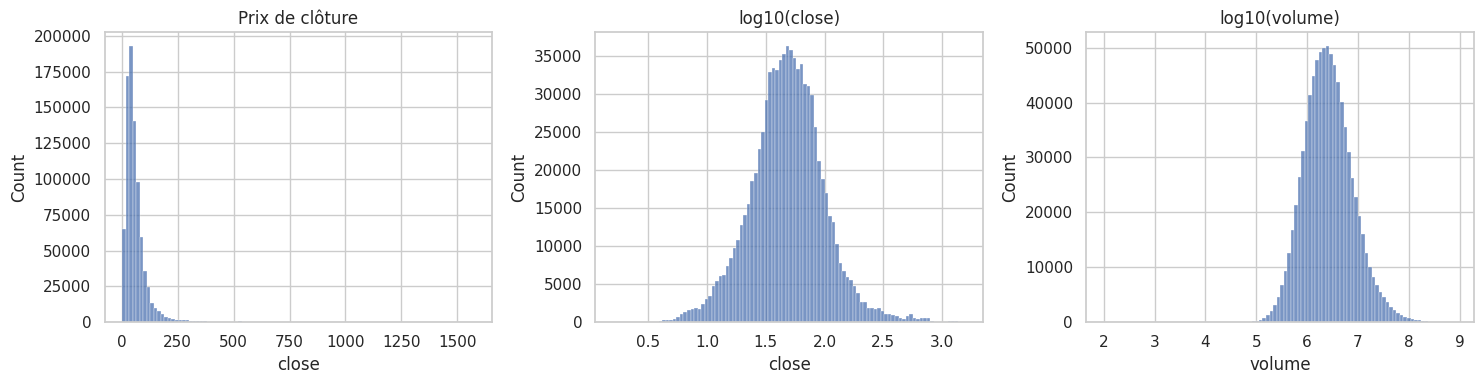

In [5]:
# 1.2 Distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df.close, bins=100, ax=axes[0]); axes[0].set_title("Prix de clôture")
sns.histplot(np.log10(df.close), bins=100, ax=axes[1]); axes[1].set_title("log10(close)")
sns.histplot(np.log10(df.volume[df.volume > 0]), bins=100, ax=axes[2]); axes[2].set_title("log10(volume)")
savefig("p1_distributions")

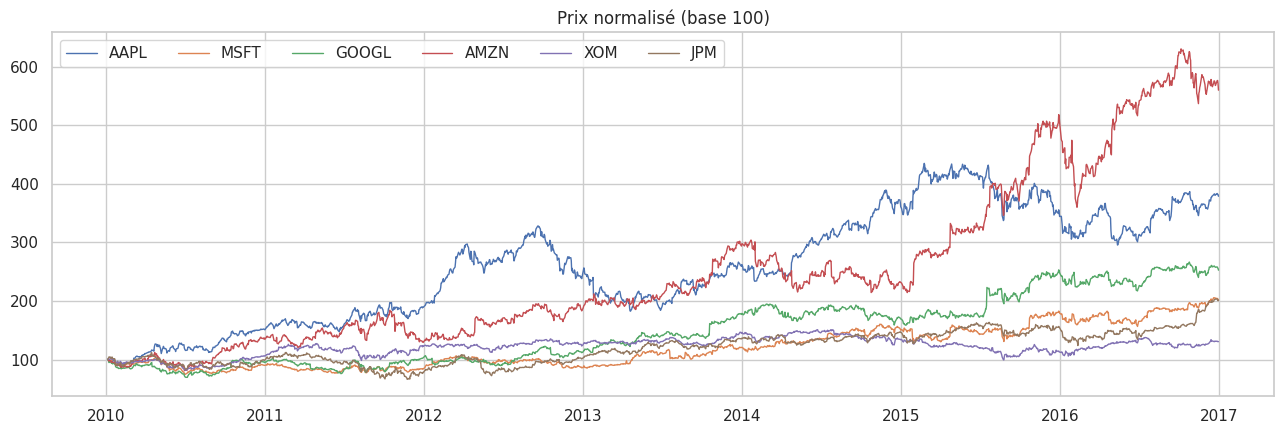

In [6]:
# 1.3 Évolution temporelle
fig, ax = plt.subplots(figsize=(13, 4.5))
for t in ["AAPL", "MSFT", "GOOGL", "AMZN", "XOM", "JPM"]:
    s = df[df.symbol == t].set_index("date").close
    ax.plot(s.index, s / s.iloc[0] * 100, label=t, lw=1)
ax.set_title("Prix normalisé (base 100)"); ax.legend(ncol=6)
savefig("p1_series")

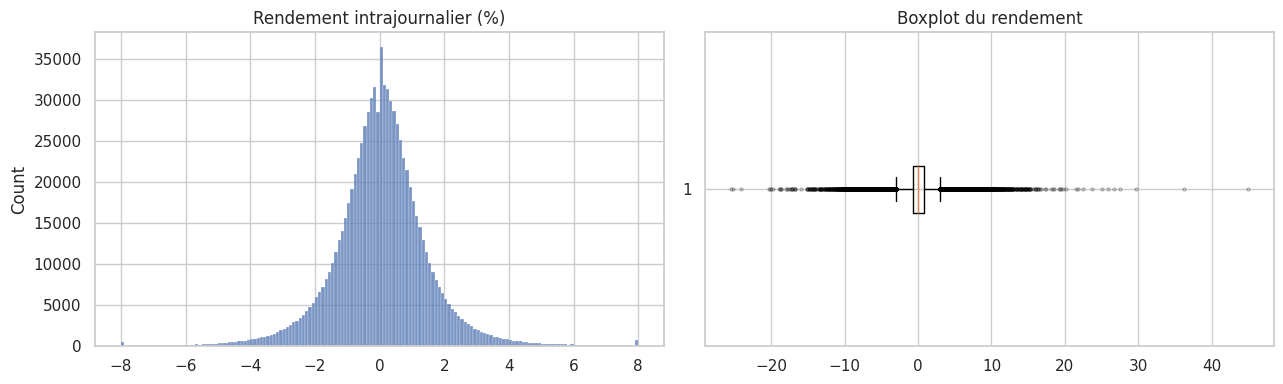

count    851264.000000
mean          0.042016
std           1.478328
min         -25.537774
25%          -0.702109
50%           0.046053
75%           0.794842
max          44.988944
dtype: float64


In [7]:
# 1.4 Rendement journalier et outliers
ret = (df.close / df.open - 1) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(ret.clip(-8, 8), bins=160, ax=axes[0]); axes[0].set_title("Rendement intrajournalier (%)")
axes[1].boxplot(ret, vert=False, flierprops=dict(markersize=2, alpha=.3)); axes[1].set_title("Boxplot du rendement")
savefig("p1_returns")
print(ret.describe())

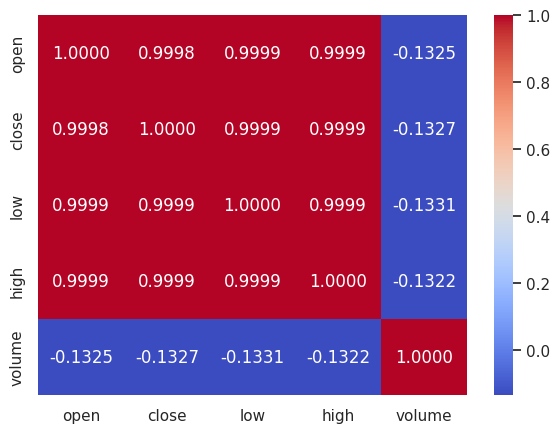

R² baseline naïve (close = open) : 0.999689289377878


In [8]:
# 1.5 Corrélations et piège de la baseline
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[["open", "close", "low", "high", "volume"]].corr(), annot=True, fmt=".4f", cmap="coolwarm")
savefig("p1_corr")
print("R² baseline naïve (close = open) :", r2_score(df.close, df.open))

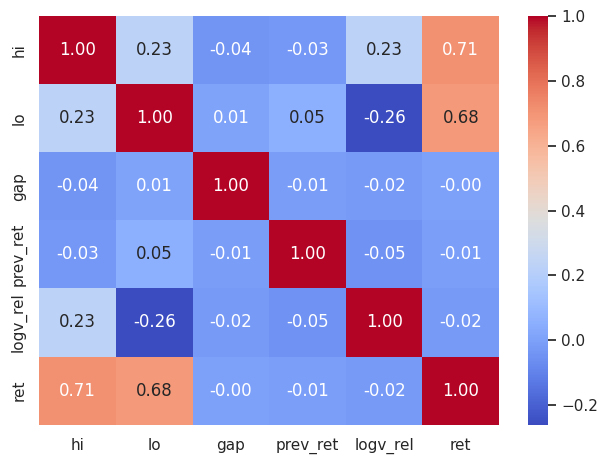

In [9]:
# ===================== QUESTION 2 — Préparation des données =====================
data = df[df.volume > 0].sort_values(["symbol", "date"]).copy()
g = data.groupby("symbol")
data["ret"] = (data.close / data.open - 1) * 100
data["hi"] = (data.high / data.open - 1) * 100
data["lo"] = (data.low / data.open - 1) * 100
data["gap"] = (data.open / g.close.shift(1) - 1) * 100
data["prev_ret"] = g.ret.shift(1)
data["logv"] = np.log(data.volume)
data["logv_rel"] = data.logv - g.logv.transform(lambda s: s.shift(1).rolling(20, min_periods=5).mean())
data = data.dropna().sort_values("date").reset_index(drop=True)

FEATURES = ["hi", "lo", "gap", "prev_ret", "logv_rel"]
TARGET = "ret"
sns.heatmap(data[FEATURES + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm"); savefig("p1_corr_features")

In [10]:
# Split temporel + écrêtage + standardisation + DataLoaders
train = data[data.date.dt.year <= 2014]
val   = data[data.date.dt.year == 2015]
test  = data[data.date.dt.year == 2016]

cols = FEATURES + [TARGET]                       # écrêtage des outliers (seuils calculés sur le train)
q_low, q_high = train[cols].quantile(0.001), train[cols].quantile(0.999)
clip = lambda d: d.assign(**{c: d[c].clip(q_low[c], q_high[c]) for c in cols})
train, val, test = clip(train), clip(val), clip(test)

scaler = StandardScaler().fit(train[FEATURES])
def to_xy(d):
    return scaler.transform(d[FEATURES]).astype("float32"), d[TARGET].values.astype("float32").reshape(-1, 1)
X_train, y_train = to_xy(train); X_val, y_val = to_xy(val); X_test, y_test = to_xy(test)

def make_loader(X, y, batch_size=512, shuffle=False):
    return DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(y)), batch_size=batch_size, shuffle=shuffle)

train_dl = make_loader(X_train, y_train, 512, shuffle=True)
eval_sets = {"train": make_loader(X_train, y_train, 8192),
             "val": make_loader(X_val, y_val, 8192),
             "test": make_loader(X_test, y_test, 8192)}
print(len(train), len(val), len(test))

597713 124912 126113


In [11]:
# Baselines à battre
def price_metrics(d, ret_pred):
    close_pred = d.open.values * (1 + ret_pred.ravel() / 100)
    return mean_squared_error(d.close, close_pred) ** 0.5, r2_score(d.close, close_pred)

lin = LinearRegression().fit(X_train, y_train)
results = {}
for name, pred in [("Naïve (ret=0)", np.zeros(len(y_test))), ("Régression linéaire", lin.predict(X_test))]:
    results[name] = {"R² ret": r2_score(y_test, pred), "RMSE prix ($)": price_metrics(test, pred)[0]}
pd.DataFrame(results).T

,R² ret,RMSE prix ($)
Naïve (ret=0),-0.002142,1.698588
Régression linéaire,0.800001,0.745082


In [12]:
# ===================== QUESTION 2 — Architecture DNN (MLP) =====================
class MLP(nn.Module):
    def __init__(self, n_inputs, hidden_layers=(64, 32), n_outputs=1,
                 activation=nn.ReLU, dropout=0.0, batchnorm=False):
        super().__init__()
        layers, prev = [], n_inputs
        for h in hidden_layers:
            lin = nn.Linear(prev, h)
            if activation in (nn.ReLU, nn.LeakyReLU, nn.ELU):
                nn.init.kaiming_uniform_(lin.weight, nonlinearity="relu")
            else:
                nn.init.xavier_uniform_(lin.weight)
            nn.init.zeros_(lin.bias)
            layers.append(lin)
            if batchnorm: layers.append(nn.BatchNorm1d(h))
            layers.append(activation())
            if dropout > 0: layers.append(nn.Dropout(dropout))
            prev = h
        out = nn.Linear(prev, n_outputs); nn.init.xavier_uniform_(out.weight)
        layers.append(out)
        self.net = nn.Sequential(*layers)

    def forward(self, X):
        return self.net(X)

print(MLP(len(FEATURES), (128, 64)))

MLP(
  (net): Sequential(
    (0): Linear(in_features=5, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [13]:
# Boucle d'entraînement (cours : zero_grad → forward → loss → backward → step) + historique + L1 + early stopping
def r2_metric(y, yhat):
    return (1 - ((y - yhat) ** 2).sum() / ((y - y.mean()) ** 2).sum()).item()

def l1_penalty(model):
    return sum(p.abs().sum() for n, p in model.named_parameters() if "weight" in n)

@torch.no_grad()
def predict_loader(model, loader):
    model.eval(); preds, ys = [], []
    for X, y in loader:
        preds.append(model(X.to(device)).cpu()); ys.append(y)
    return torch.cat(preds), torch.cat(ys)

def fit(model, train_dl, eval_sets, criterion, optimizer, epochs, metric_fn=r2_metric,
        l1_lambda=0.0, patience=None, monitor="val", desc="Training"):
    model.to(device)
    hist = {k: {"loss": [], "metric": []} for k in eval_sets}
    best_loss, best_state, best_epoch, wait = np.inf, None, 0, 0
    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        for X, y in train_dl:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(X), y)
            if l1_lambda > 0:
                loss = loss + l1_lambda * l1_penalty(model)
            loss.backward()
            optimizer.step()
        for k, dl in eval_sets.items():
            yhat, y = predict_loader(model, dl)
            hist[k]["loss"].append(criterion(yhat, y).item())
            hist[k]["metric"].append(metric_fn(y, yhat))
        if patience is not None:
            cur = hist[monitor]["loss"][-1]
            if cur < best_loss - 1e-5:
                best_loss, best_state, best_epoch, wait = cur, copy.deepcopy(model.state_dict()), epoch, 0
            else:
                wait += 1
                if wait >= patience:
                    print(f"  Early stopping epoch {epoch+1} (meilleure : {best_epoch+1})"); break
    print(f"  {desc} : {epoch+1} epochs en {time.time()-t0:.0f} s")
    if best_state is not None: model.load_state_dict(best_state)
    hist["best_epoch"] = best_epoch if patience is not None else epoch
    return hist

In [14]:
# Sanity check : le réseau doit apprendre par cœur 64 exemples (loss → ~0)
set_seed(0)
tiny = make_loader(X_train[:64], y_train[:64], 64, shuffle=True)
m = MLP(len(FEATURES), (128, 64))
h = fit(m, tiny, {"train": tiny}, nn.MSELoss(), torch.optim.Adam(m.parameters(), lr=1e-2), 300, desc="sanity")
print(h["train"]["loss"][0], "→", h["train"]["loss"][-1])

  sanity : 300 epochs en 2 s
4.867743968963623 → 0.00016139472427312285


In [15]:
# ===================== QUESTION 3 — GridSearch (skorch + TimeSeriesSplit) =====================
class SGDMomentum(torch.optim.SGD):
    def __init__(self, params, lr=0.01, **kw):
        super().__init__(params, lr=lr, momentum=0.9, **kw)

gs_idx = np.sort(np.random.RandomState(42).choice(len(X_train), 60_000, replace=False))
X_gs, y_gs = X_train[gs_idx], y_train[gs_idx]

net = NeuralNetRegressor(module=MLP, module__n_inputs=len(FEATURES), criterion=nn.MSELoss,
                         batch_size=512, train_split=None, verbose=0, iterator_train__shuffle=True,
                         device=str(device))
param_grid = {
    "module__hidden_layers": [(64, 32), (128, 64, 32)],
    "module__activation": [nn.ReLU, nn.Tanh],
    "optimizer": [SGDMomentum, torch.optim.RMSprop, torch.optim.Adam],
    "lr": [1e-3, 1e-2],
    "max_epochs": [10, 20],
}
t0 = time.time()
gs = GridSearchCV(net, param_grid, cv=TimeSeriesSplit(n_splits=3), scoring="r2", refit=False, verbose=1)
gs.fit(X_gs, y_gs)
print(f"Durée : {(time.time()-t0)/60:.1f} min")
print("Meilleur R² CV :", gs.best_score_)
print("Meilleurs hyper-paramètres :", gs.best_params_)

Fitting 3 folds for each of 48 candidates, totalling 144 fits
Durée : 12.5 min
Meilleur R² CV : 0.8052325050036112
Meilleurs hyper-paramètres : {'lr': 0.01, 'max_epochs': 10, 'module__activation': <class 'torch.nn.modules.activation.Tanh'>, 'module__hidden_layers': (128, 64, 32), 'optimizer': <class '__main__.SGDMomentum'>}


,archi,activation,optimiseur,lr,epochs,R² moyen,std,rang
33,"(128, 64, 32)",Tanh,SGDMomentum,0.010,10,0.805233,0.004506,1
20,"(64, 32)",Tanh,Adam,0.001,20,0.805104,0.002824,2
23,"(128, 64, 32)",Tanh,Adam,0.001,20,0.804696,0.003985,3
11,"(128, 64, 32)",Tanh,Adam,0.001,10,0.804453,0.003290,4
42,"(64, 32)",Tanh,SGDMomentum,0.010,20,0.804094,0.004846,5
37,"(64, 32)",ReLU,RMSprop,0.010,20,0.804005,0.001751,6
41,"(128, 64, 32)",ReLU,Adam,0.010,20,0.803858,0.005162,7
32,"(64, 32)",Tanh,Adam,0.010,10,0.803634,0.004240,8
38,"(64, 32)",ReLU,Adam,0.010,20,0.803607,0.005210,9
24,"(64, 32)",ReLU,SGDMomentum,0.010,10,0.803493,0.005021,10


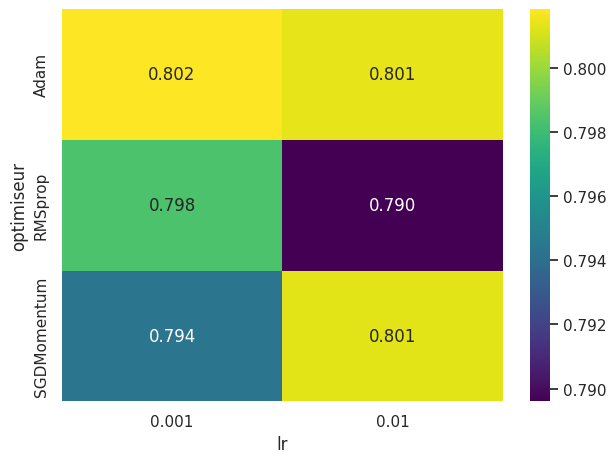

In [16]:
res = pd.DataFrame(gs.cv_results_)
short = lambda v: v.__name__ if hasattr(v, "__name__") else v
table = pd.DataFrame({"archi": res.param_module__hidden_layers.astype(str),
                      "activation": res.param_module__activation.map(short),
                      "optimiseur": res.param_optimizer.map(short), "lr": res.param_lr,
                      "epochs": res.param_max_epochs, "R² moyen": res.mean_test_score,
                      "std": res.std_test_score, "rang": res.rank_test_score}).sort_values("rang")
display(table.head(10))
sns.heatmap(table.pivot_table(index="optimiseur", columns="lr", values="R² moyen", aggfunc="mean"),
            annot=True, fmt=".3f", cmap="viridis"); savefig("p1_gridsearch")

  Modèle de base : 40 epochs en 519 s


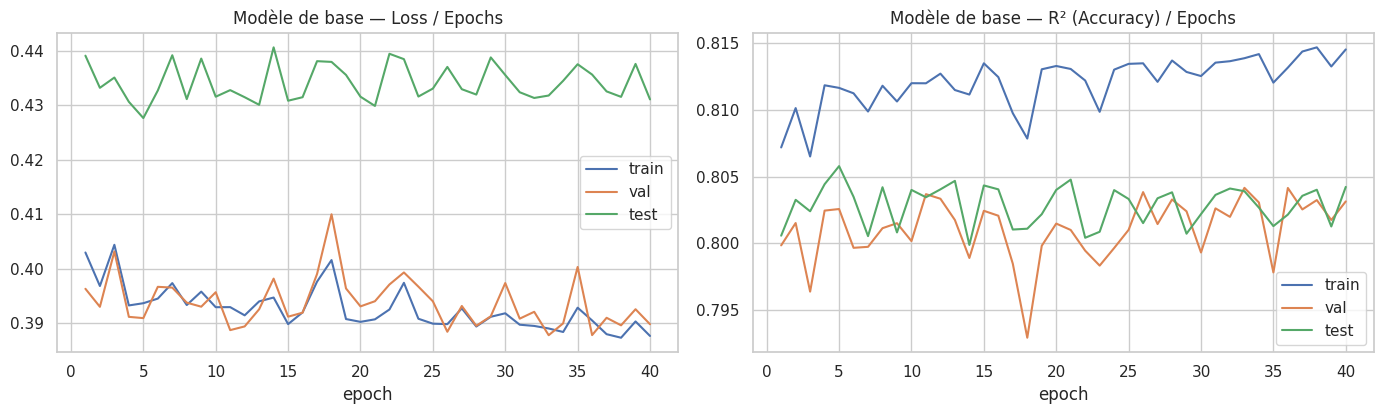

In [17]:
# ===================== QUESTION 4 — Courbes Loss/Epochs et R²(Accuracy)/Epochs =====================
bp = gs.best_params_
BEST = dict(hidden_layers=bp["module__hidden_layers"], activation=bp["module__activation"])
BEST_OPT, BEST_LR = bp["optimizer"], bp["lr"]
EPOCHS = 40

set_seed(42)
base_model = MLP(len(FEATURES), **BEST)
hist_base = fit(base_model, train_dl, eval_sets, nn.MSELoss(),
                BEST_OPT(base_model.parameters(), lr=BEST_LR), EPOCHS, desc="Modèle de base")

def plot_history(hist, title, fname, sets=("train", "test")):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
    for k in sets:
        ep = range(1, len(hist[k]["loss"]) + 1)
        axes[0].plot(ep, hist[k]["loss"], label=k); axes[1].plot(ep, hist[k]["metric"], label=k)
    axes[0].set_title(f"{title} — Loss / Epochs"); axes[1].set_title(f"{title} — R² (Accuracy) / Epochs")
    for ax in axes: ax.set_xlabel("epoch"); ax.legend()
    savefig(fname)

plot_history(hist_base, "Modèle de base", "p1_curves_base", sets=("train", "val", "test"))

,R² ret,RMSE prix ($)
Naïve (ret=0),-0.002142,1.698588
Régression linéaire,0.800001,0.745082
DNN (base),0.804225,0.728071


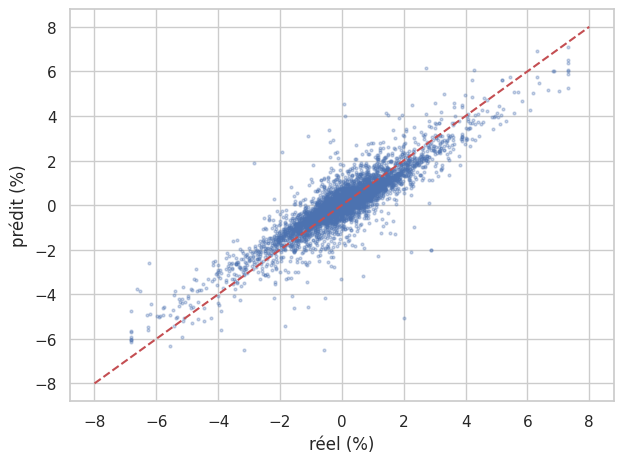

In [18]:
pred_test = predict_loader(base_model, eval_sets["test"])[0].numpy()
results["DNN (base)"] = {"R² ret": r2_score(y_test, pred_test), "RMSE prix ($)": price_metrics(test, pred_test)[0]}
display(pd.DataFrame(results).T)

sub = np.random.RandomState(0).choice(len(y_test), 5000, replace=False)
plt.scatter(y_test[sub], pred_test[sub], s=4, alpha=.3); plt.plot([-8, 8], [-8, 8], "r--")
plt.xlabel("réel (%)"); plt.ylabel("prédit (%)"); savefig("p1_pred_vs_real")

In [ ]:
# ===================== QUESTION 5 — Régularisation (dataset complet) =====================
def train_variant(name, hidden=None, dropout=0.0, batchnorm=False, weight_decay=0.0, l1=0.0, patience=None,
                  tr_dl=train_dl, sets=eval_sets, epochs=EPOCHS, opt=None, lr=None):
    set_seed(42)
    model = MLP(len(FEATURES), hidden_layers=hidden or BEST["hidden_layers"], activation=BEST["activation"],
                dropout=dropout, batchnorm=batchnorm)
    optim = (opt or BEST_OPT)(model.parameters(), lr=lr or BEST_LR, weight_decay=weight_decay)
    return model, fit(model, tr_dl, sets, nn.MSELoss(), optim, epochs, l1_lambda=l1, patience=patience, desc=name)

variants = {"L2 (1e-4)": dict(weight_decay=1e-4), "L1 (1e-6)": dict(l1=1e-6),
            "Dropout (0.2)": dict(dropout=0.2), "Early stopping": dict(patience=5),
            "BN + Dropout + L2 + ES": dict(batchnorm=True, dropout=0.1, weight_decay=1e-4, patience=5)}
models, hists = {"Base": base_model}, {"Base": hist_base}
for name, kw in variants.items():
    models[name], hists[name] = train_variant(name, **kw)

def summarize(h):
    e = h["best_epoch"]
    return {"epochs": len(h["train"]["loss"]), "R² train": h["train"]["metric"][e], "R² test": h["test"]["metric"][e],
            "écart train−test": h["train"]["metric"][e] - h["test"]["metric"][e], "loss test": h["test"]["loss"][e]}
display(pd.DataFrame({n: summarize(h) for n, h in hists.items()}).T.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for n, h in hists.items():
    axes[0].plot(h["test"]["loss"], label=n); axes[1].plot(h["test"]["metric"], label=n)
axes[0].set_title("Loss test / Epochs"); axes[1].set_title("R² test / Epochs"); axes[0].legend(fontsize=8)
savefig("p1_regularization_full")

  L2 (1e-4) : 40 epochs en 521 s
  L1 (1e-6) : 40 epochs en 542 s


In [ ]:
# QUESTION 5 (suite) — Petit dataset + gros réseau, pour VOIR l'effet de la régularisation
idx = np.random.RandomState(1).choice(len(X_train), 2000, replace=False)
small_tr = make_loader(X_train[idx], y_train[idx], 64, shuffle=True)
small_sets = {"train": make_loader(X_train[idx], y_train[idx], 2000),
              "val": make_loader(X_val[:20000], y_val[:20000], 8192),
              "test": make_loader(X_test[:20000], y_test[:20000], 8192)}
cfg = dict(hidden=(256, 256, 128), tr_dl=small_tr, sets=small_sets, epochs=200, opt=torch.optim.Adam, lr=1e-3)
small_variants = {"Base": {}, "L2 (1e-2)": dict(weight_decay=1e-2), "L1 (1e-4)": dict(l1=1e-4),
                  "Dropout (0.3)": dict(dropout=0.3), "Early stopping": dict(patience=15)}
small_models, small_hists = {}, {}
for n, kw in small_variants.items():
    small_models[n], small_hists[n] = train_variant(n, **cfg, **kw)
display(pd.DataFrame({n: summarize(h) for n, h in small_hists.items()}).T.round(4))

fig, axes = plt.subplots(1, 5, figsize=(20, 3.8), sharey=True)
for ax, (n, h) in zip(axes, small_hists.items()):
    ax.plot(h["train"]["loss"], label="train"); ax.plot(h["test"]["loss"], label="test")
    ax.set_title(n); ax.set_ylim(0, 1.2)
axes[0].legend(); savefig("p1_regularization_small")